In [64]:
import pandas as pd

import numpy as np

from sklearn.preprocessing import LabelEncoder

from collections import OrderedDict

from imblearn.over_sampling import RandomOverSampler,SMOTE

import matplotlib.pyplot as plt

import seaborn as sns

import scipy.stats as sci

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV , learning_curve,KFold

from sklearn.metrics import mean_squared_error , r2_score

from sklearn.linear_model import LinearRegression , Lasso , Ridge

from sklearn.tree import DecisionTreeRegressor 

from sklearn.neighbors import KNeighborsRegressor

from sklearn.svm import SVR

from sklearn.ensemble import RandomForestRegressor , AdaBoostRegressor,GradientBoostingRegressor

import xgboost 

from xgboost import XGBRegressor


In [2]:
df = pd.read_csv("Bank data.csv")

In [3]:
df.head()

,Cust No.,First Name,Surname,Credit Score,Geography,Gender,Age,Tenure,Balance,Num Of Policies,Credit Card,Active Member,Salary,Exited
0,1,Walter,Hargrave,619,France,Female,42,2.0,NaN,1.0,Yes,Yes,101349,1
1,2,Daniel,Hill,608,Spain,Female,41,1.0,83807.86,1.0,No,Yes,112543,0
2,3,Melissa,Onio,502,France,Female,42,8.0,159660.80,3.0,Yes,No,113932,1
3,4,Miley,Boni,699,France,Female,39,1.0,NaN,2.0,No,No,93827,0
4,5,James,Mitchell,850,Spain,Female,43,2.0,125510.82,1.0,Yes,Yes,79084,0


In [4]:
df.shape

(10071, 14)

In [5]:
df.dropna(inplace = True)

In [6]:
df.shape

(6270, 14)

In [7]:
df.drop("Cust No.",axis = 1,inplace=True)
df.drop("First Name",axis = 1,inplace=True)
df.drop("Surname",axis = 1,inplace=True)

In [8]:
df.head(2)

,Credit Score,Geography,Gender,Age,Tenure,Balance,Num Of Policies,Credit Card,Active Member,Salary,Exited
1,608,Spain,Female,41,1.0,83807.86,1.0,No,Yes,112543,0
2,502,France,Female,42,8.0,159660.80,3.0,Yes,No,113932,1


In [9]:
le = LabelEncoder()

for col in df.columns:
    if df[col].dtype == "O":
        df[col] = le.fit_transform(df[col])

In [10]:
df.tail()

,Credit Score,Geography,Gender,Age,Tenure,Balance,Num Of Policies,Credit Card,Active Member,Salary,Exited
10064,711,2,1,86,1.0,161425.0,2.0,1,0,51518,1
10065,447,0,1,31,8.0,79591.0,3.0,0,1,159857,0
10066,777,0,0,35,3.0,80701.0,2.0,1,1,156120,0
10068,450,0,1,60,9.0,1053.0,4.0,1,1,86961,0
10069,819,1,1,45,3.0,94661.0,3.0,1,1,89433,1


In [11]:
x = df.drop("Exited",axis = 1)
y = df[["Exited"]]

In [12]:
y.value_counts()

Exited
0         4738
1         1532
dtype: int64

### SMOTE

In [13]:
sm = SMOTE()

In [14]:
sm_x,sm_y = sm.fit_resample(x,y)

In [51]:
sm_y

,Exited
0,0
1,1
2,0
3,1
4,1
...,...
9471,1
9472,1
9473,1
9474,1


(      Credit Score  Geography  Gender  Age    Tenure        Balance  \
 0              608          2       0   41  1.000000   83807.860000   
 1              502          0       0   42  8.000000  159660.800000   
 2              850          2       0   43  2.000000  125510.820000   
 3              645          2       1   44  8.000000  113755.780000   
 4              376          1       0   29  4.000000  115046.740000   
 ...            ...        ...     ...  ...       ...            ...   
 9471           639          0       0   44  1.491766  140607.955767   
 9472           639          1       0   40  8.684121  137733.450732   
 9473           675          0       1   46  2.584447   96372.481046   
 9474           823          1       0   38  4.732004  167396.044961   
 9475           615          0       0   45  6.114753  128378.484304   
 
       Num Of Policies  Credit Card  Active Member  Salary  
 0            1.000000            0              1  112543  
 1          

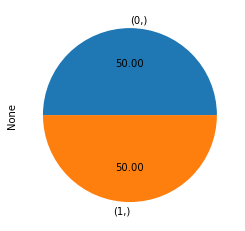

In [15]:
sm_x,sm_y.value_counts().plot.pie(autopct = "%.2f")

In [16]:
df_x = pd.DataFrame(sm_x)

In [17]:
df_y = pd.DataFrame(sm_y)

In [18]:
df_new = df_x.join(df_y,how = "left")

In [19]:
df_new

,Credit Score,Geography,Gender,Age,Tenure,Balance,Num Of Policies,Credit Card,Active Member,Salary,Exited
0,608,2,0,41,1.000000,83807.860000,1.000000,0,1,112543,0
1,502,0,0,42,8.000000,159660.800000,3.000000,1,0,113932,1
2,850,2,0,43,2.000000,125510.820000,1.000000,1,1,79084,0
3,645,2,1,44,8.000000,113755.780000,2.000000,1,0,149757,1
4,376,1,0,29,4.000000,115046.740000,4.000000,1,0,119347,1
...,...,...,...,...,...,...,...,...,...,...,...
9471,639,0,0,44,1.491766,140607.955767,1.000000,1,0,190064,1
9472,639,1,0,40,8.684121,137733.450732,1.000000,1,0,117231,1
9473,675,0,1,46,2.584447,96372.481046,1.207777,1,1,133299,1
9474,823,1,0,38,4.732004,167396.044961,2.244001,0,0,156019,1


### Descriptive Statistics

In [20]:
def custom_summary(df):
    
    cols = []
    
    for col in df.columns:
        if df[col].dtype != 'O':
            cols.append(col)
            
        
    # Creating a resultant Dataframe
    
    results = pd.DataFrame(columns=cols,index=['DataType','count','Minimum','First Quartile','Mean','Median','Third Quartile','Maximum',
                          'Standard Deviation','Skewness','Kurtosis','Range','IQR','Skewness Type',
                          'Kurtosis Type','Outlier Comment','Outlier Percentage'])
    for i in results.columns:
        results.loc['DataType',i] = df[i].dtype
        results.loc['count',i] = df[i].count()        
        results.loc['Minimum',i] = df[i].min()        
        results.loc['First Quartile',i] = df[i].quantile(0.25)        
        results.loc['Mean',i] = df[i].mean()        
        results.loc['Median',i] = df[i].median()       
        results.loc['Third Quartile',i] = df[i].quantile(0.75)        
        results.loc['Maximum',i] = df[i].max()        
        results.loc['Standard Deviation',i] = df[i].std() 
        results.loc['Skewness',i] = df[i].skew()
        results.loc['Kurtosis',i] = df[i].kurt()        
        results.loc['Range',i] = df[i].max() - df[i].min()
        results.loc['IQR',i] = df[i].quantile(0.75) - df[i].quantile(0.25)
        
        
        
        if results.loc['Skewness',i] <= -1:
            skew_type = 'Highly Negatively Skewed'
        elif -1 < results.loc['Skewness',i] <= -0.5:
            skew_type = 'Moderately Negatively Skewed'
        elif -0.5 < results.loc['Skewness',i] < 0:
            skew_type = 'Approx Normal Distribution (-ve)'
        elif 0 <= results.loc['Skewness',i] < 0.5:
            skew_type = 'Approx Normal Distribution (+ve)'
        elif 0.5<= results.loc['Skewness',i] < 1:
            skew_type = 'Moderately Positively Skewed'
        elif results.loc['Skewness',i] >= 1:
            skew_type = 'Highly Positively Skewed'
        else:
            skew_type = 'Error'
        
        results.loc['Skewness Type',i] = skew_type
        
        
        
        if results.loc['Kurtosis',i] <= -1:
            kurt_type = 'Highly Platykurtic Curve'
        elif -1 < results.loc['Kurtosis',i] <= -0.5:
            kurt_type = 'Moderately Platykurtic Curve'
        elif -0.5 < results.loc['Kurtosis',i] <= 0.5:
            kurt_type = 'Mesokurtic Curve'
        elif 0.5<= results.loc['Kurtosis',i] < 1:
            kurt_type = 'Moderately Leptokurtic Curve'
        elif results.loc['Kurtosis',i] >= 1:
            kurt_type = 'Highly Leptokurtic Curve'
        else:
            kurt_type = 'Error'
        
        results.loc['Kurtosis Type',i] = kurt_type
        
        
        
        lower_limit = results.loc['First Quartile',i] - (1.5*results.loc['IQR',i])
        upper_limit = results.loc['Third Quartile',i] + (1.5*results.loc['IQR',i])
        
        if len([x for x in df[i] if x < lower_limit or x > upper_limit]) > 0 :
            outlier_label = 'Have Outliers'
            outlier_percentage = len([x for x in df[i] if (x < lower_limit) or (x > upper_limit)])/len(df)
        else:
            outlier_label = 'No Outliers'
            outlier_percentage = 0
            
        results.loc['Outlier Comment',i] = outlier_label
        results.loc['Outlier Percentage',i] = outlier_percentage
        
      
    
    display(results)

In [21]:
custom_summary(df_new)

,Credit Score,Geography,Gender,Age,Tenure,Balance,Num Of Policies,Credit Card,Active Member,Salary,Exited
DataType,int64,int32,int32,int64,float64,float64,float64,int32,int32,int64,int64
count,9476,9476,9476,9476,9476,9476,9476,9476,9476,9476,9476
Minimum,350,0,0,18,0.0,1053.0,1.0,0,0,12,0
First Quartile,585.0,0.0,0.0,34.0,3.0,101275.315,1.0,0.0,0.0,51363.5,0.0
Mean,648.793584,0.716969,0.430456,41.078725,4.976915,120032.591012,1.415297,0.626003,0.381385,100964.470452,0.5
Median,650.0,1.0,0.0,40.0,5.0,119874.68,1.0,1.0,0.0,101853.0,0.5
Third Quartile,712.0,1.0,1.0,47.0,7.0,139226.409672,2.0,1.0,1.0,150694.0,1.0
Maximum,850,2,1,92,10.0,250898.09,4.0,1,1,199971,1
Standard Deviation,92.351879,0.700012,0.495166,10.179659,2.751156,30581.082677,0.610315,0.483888,0.485752,57714.236405,0.500026
Skewness,-0.077459,0.453962,0.280951,0.635777,0.02465,0.008984,1.489904,-0.520902,0.488481,-0.019903,0.0


### Outlier Treatment

In [22]:
def outlier_treatment(data,col,strategy = "median",method = "quartile"):
    
    col_data = data[col]
    
 # Finding out the Outliers

    if method == "quartile" :
        q1 = data[col].quantile(0.25)
        q2 = data[col].quantile(0.5)
        q3 = data[col].quantile(0.75)
        
        iqr = q3 - q1
        
        low_limit = q1 - 1.5*iqr
        up_limit = q3 + 1.5*iqr
        
    elif method == "standard deviation":
        
        std_dev = data[col].std()
        col_mean = data[col].mean()
        
        lower_limit = col_mean - 2*std_dev
        upper_limit = col_mean + 2*std_dev
        
    else :
        
        print("Pass the correct method")
        
# Replacing the Outliers

# 1)Finding the location of all the data points where col_data < low_limit and > up_limit

    outliers = data.loc[(col_data < low_limit) | (col_data > up_limit) , col] 
    
    outlier_density = outliers / len(data)
    
    if len(outliers) == 0:
        
        print(f"column {col} does not have any outliers")
    
    else :
        
        print(f"column {col} has outliers and they are ",outliers)
        
# 2)Replacing the ouliers with median or median
        
    if strategy == "median":
        
        data.loc[(col_data < low_limit) | (col_data > up_limit) , col] = data[col].median()
        
    elif strategy == "mean":
        
        data.loc[(col_data < low_limit) | (col_data > up_limit) , col] = data[col].mean()
        
    else:
        print("Pass the correct strategy")
        
        
    return data
        
        

In [23]:
for col in df_new.columns:
    outlier_treatment(df_new,col)

column Credit Score has outliers and they are  4       376
689     363
829     359
965     350
1098    350
1177    358
1514    351
1579    365
3248    386
3383    383
5077    367
6233    380
6241    376
6244    363
6404    364
7641    377
8632    387
8867    370
9167    390
Name: Credit Score, dtype: int64
column Geography does not have any outliers
column Gender does not have any outliers
column Age has outliers and they are  97      73
145     67
151     67
231     75
445     67
        ..
8336    67
8375    82
8694    67
9071    80
9087    70
Name: Age, Length: 166, dtype: int64
column Tenure does not have any outliers
column Balance has outliers and they are  35       40685.920000
87      213146.200000
91       40915.550000
158      37266.670000
228      40105.510000
            ...      
9205     24023.105126
9247     19853.502150
9357     23684.865115
9387    220368.924931
9460     29006.374095
Name: Balance, Length: 172, dtype: float64
column Num Of Policies has outliers and the

In [24]:
custom_summary(df_new)

,Credit Score,Geography,Gender,Age,Tenure,Balance,Num Of Policies,Credit Card,Active Member,Salary,Exited
DataType,int64,int32,int32,int64,float64,float64,float64,int32,int32,int64,float64
count,9476,9476,9476,9476,9476,9476,9476,9476,9476,9476,9476
Minimum,395,0,0,18,0.0,44361.890916,1.0,0,0,12,0.0
First Quartile,586.0,0.0,0.0,34.0,3.0,102272.6675,1.0,0.0,0.0,51363.5,0.0
Mean,649.356585,0.716969,0.430456,40.50707,4.976915,120046.728327,1.384881,0.626003,0.381385,100964.470452,0.5
Median,650.0,1.0,0.0,40.0,5.0,119874.68,1.0,1.0,0.0,101853.0,0.5
Third Quartile,712.0,1.0,1.0,47.0,7.0,138163.6825,2.0,1.0,1.0,150694.0,1.0
Maximum,850,2,1,66,10.0,195926.39,3.421205,1,1,199971,1.0
Standard Deviation,91.495911,0.700012,0.495166,9.237577,2.751156,28080.720518,0.555726,0.483888,0.485752,57714.236405,0.500026
Skewness,-0.040554,0.453962,0.280951,0.267549,0.02465,-0.003198,1.196678,-0.520902,0.488481,-0.019903,0.0


In [25]:
def odt_plots(data,col):
    
    # Building three axis(f-->canvas, ax1,ax2,ax3 --> 3 axis)
    
    f,(ax1,ax2,ax3) = plt.subplots(1,3,figsize = (15,15))
    
    # plotting the box plot on the first axis
    
    sns.boxplot(data[col] , ax = ax1 )
    ax1.set_title("Box plot for " + col )
    ax1.set_xlabel("Box plot ")
    ax1.set_ylabel("Values")
    
    
    # Plotting histogram with outliers
    
    ## sci.norm -> shows how the data looks if it is normally distributed
    
    sns.distplot(data[col] , ax = ax2 , fit  = sci.norm , color="red")
    # axvline-> vertical line
    ax2.axvline(data[col].mean(),color = "orange")   
    ax2.axvline(data[col].median() ,color = "black" , linestyle = "solid")
    ax2.set_title("Histogram for " + col + " with outliers")
    ax2.set_xlabel("Density")
    ax2.set_ylabel("Values")
    
    # Plotting Histogram without Outiers
    
    y = outlier_treatment(data,col)
    
    sns.distplot(y[col] , ax = ax3 ,fit  = sci.norm , color="green")
    ax3.axvline(y[col].mean(),color = "orange")
    ax3.axvline(y[col].median() ,color = "black" , linestyle = "solid")
    ax3.set_title("Histogram for " + col + " without outliers")
    ax3.set_xlabel("Density")
    ax3.set_ylabel("Values")

C:\Users\My PC\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(
C:\Users\My PC\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


column Credit Score has outliers and they are  3845    395
Name: Credit Score, dtype: int64


C:\Users\My PC\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
C:\Users\My PC\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(
C:\Users\My PC\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  w

column Geography does not have any outliers


C:\Users\My PC\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
C:\Users\My PC\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(
C:\Users\My PC\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  w

column Gender does not have any outliers


... (9 outputs left out)

column Credit Card does not have any outliers
column Active Member does not have any outliers


C:\Users\My PC\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(
C:\Users\My PC\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
C:\Users\My PC\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  w

column Salary does not have any outliers
column Exited does not have any outliers


C:\Users\My PC\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(
C:\Users\My PC\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
C:\Users\My PC\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  w

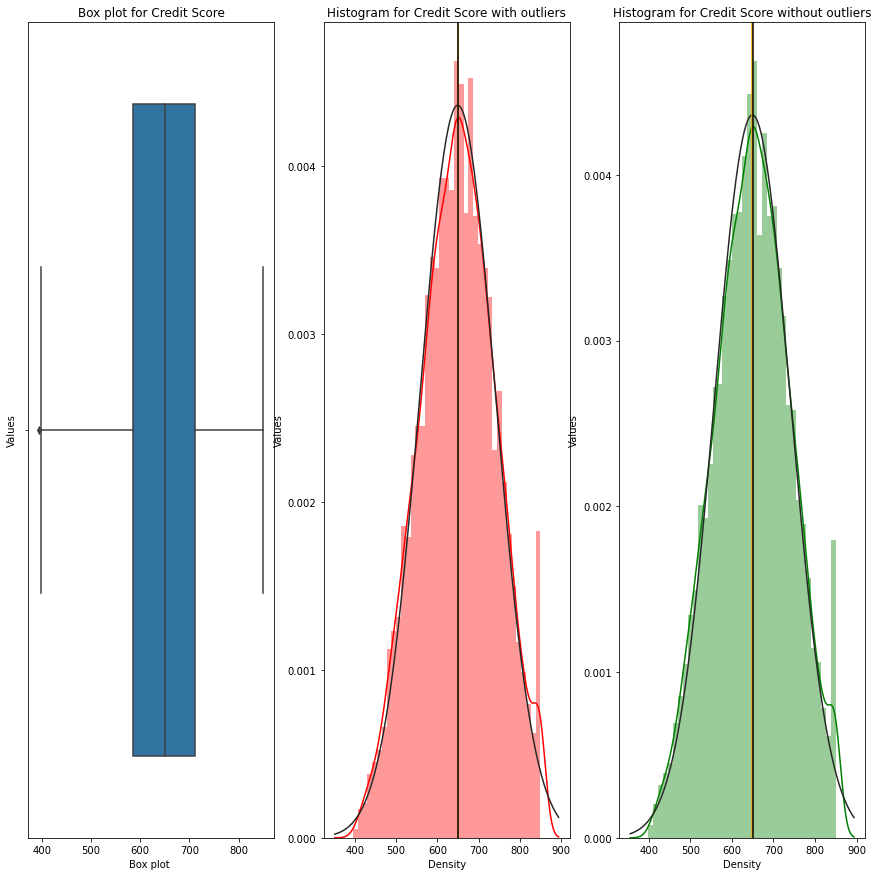

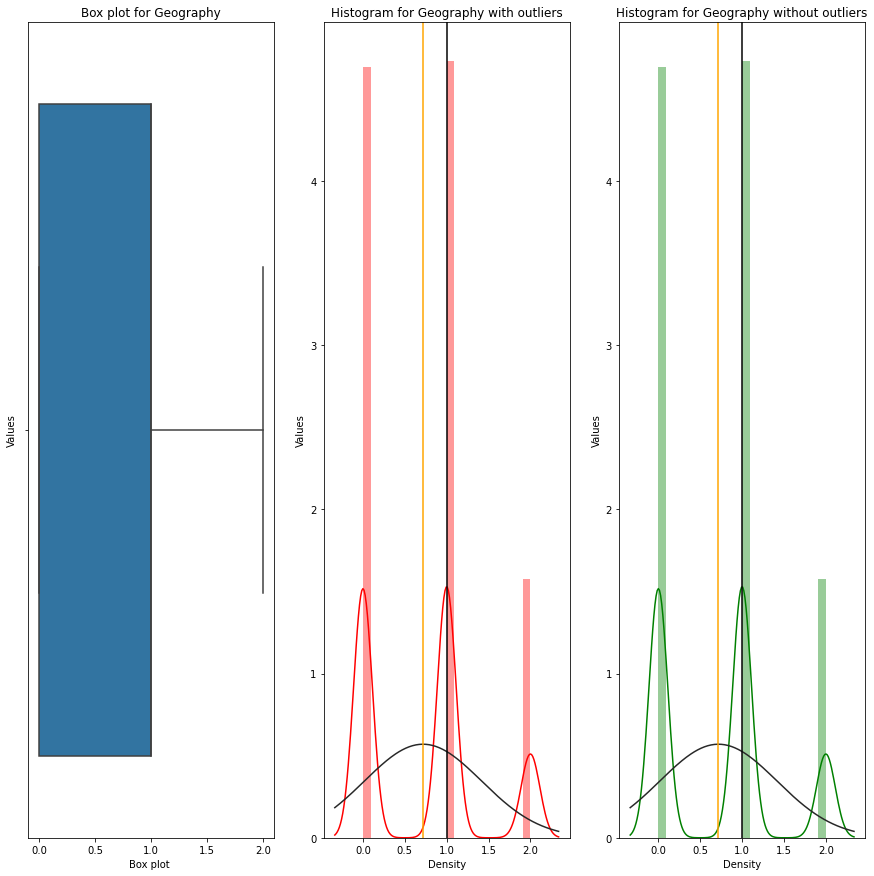

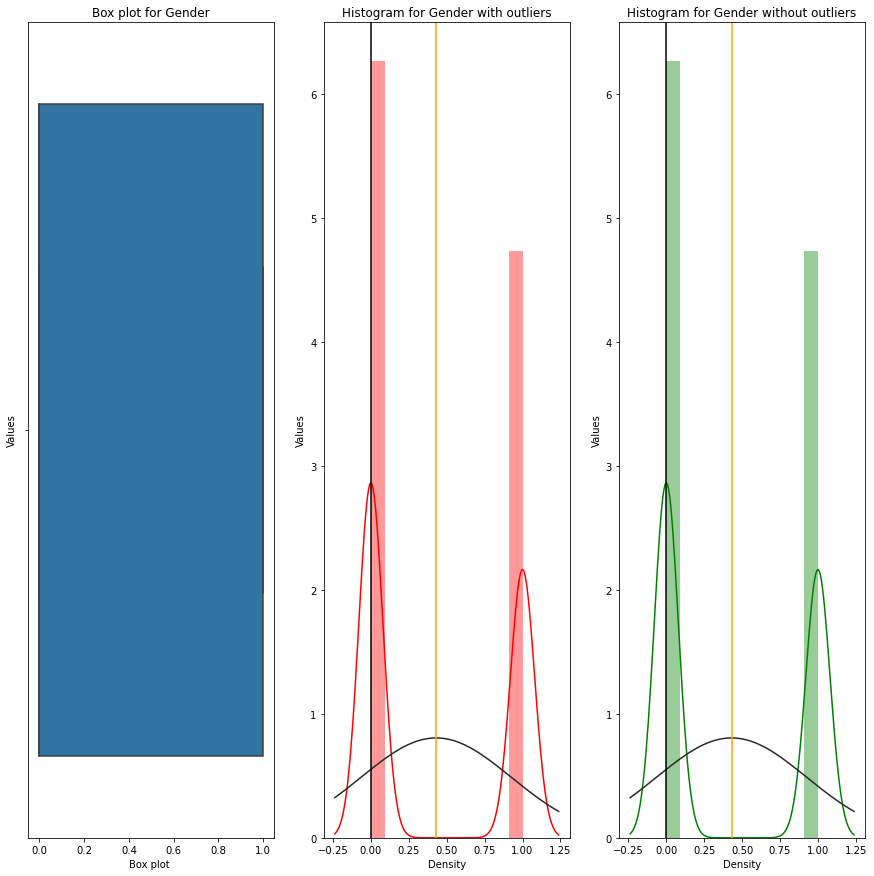

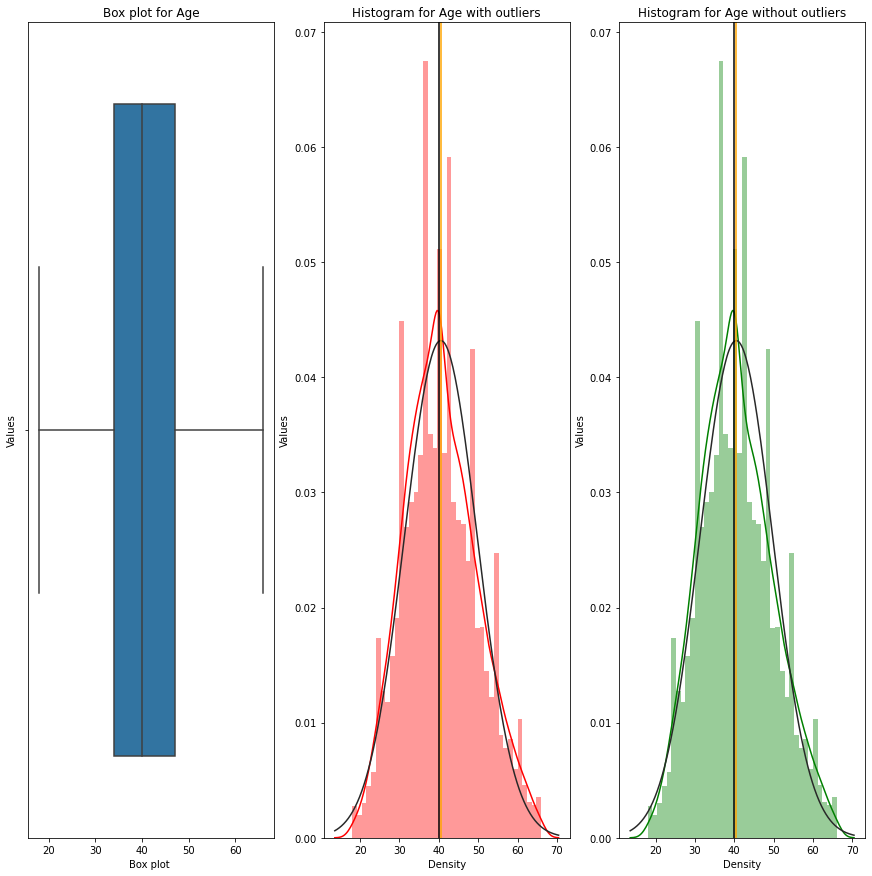

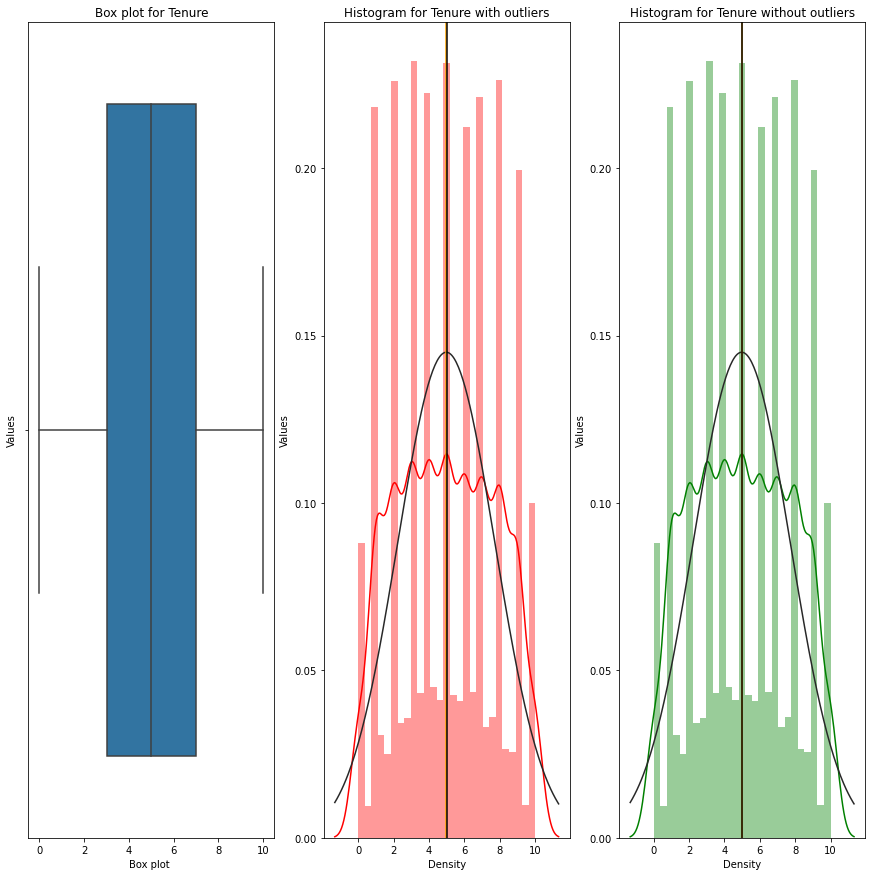

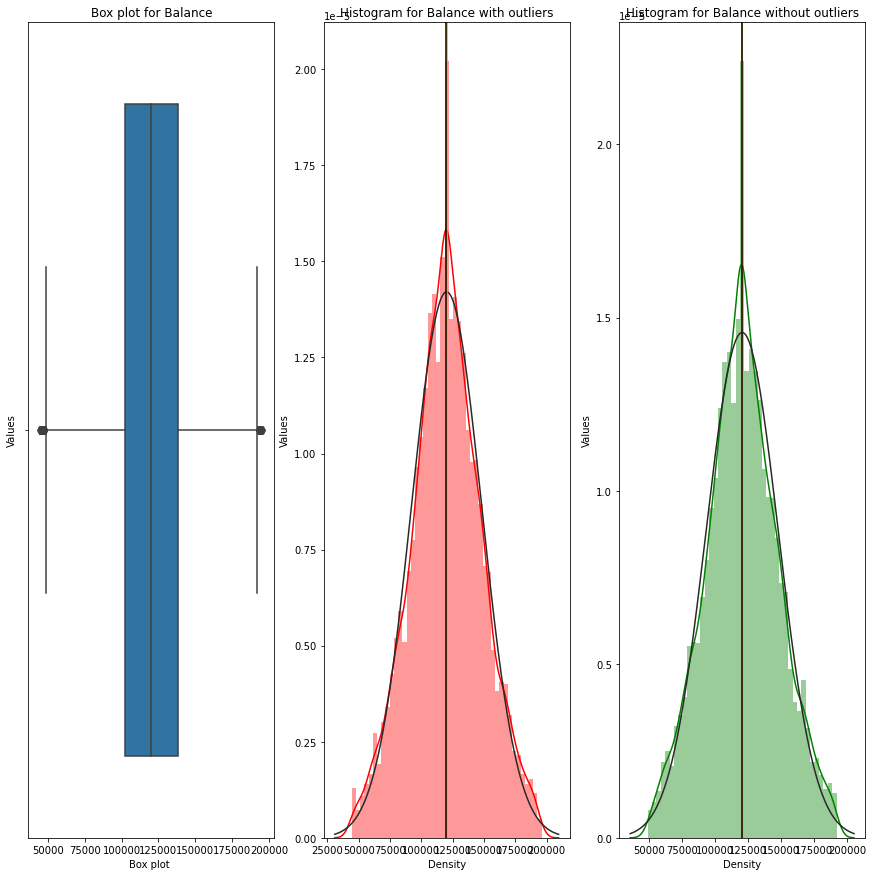

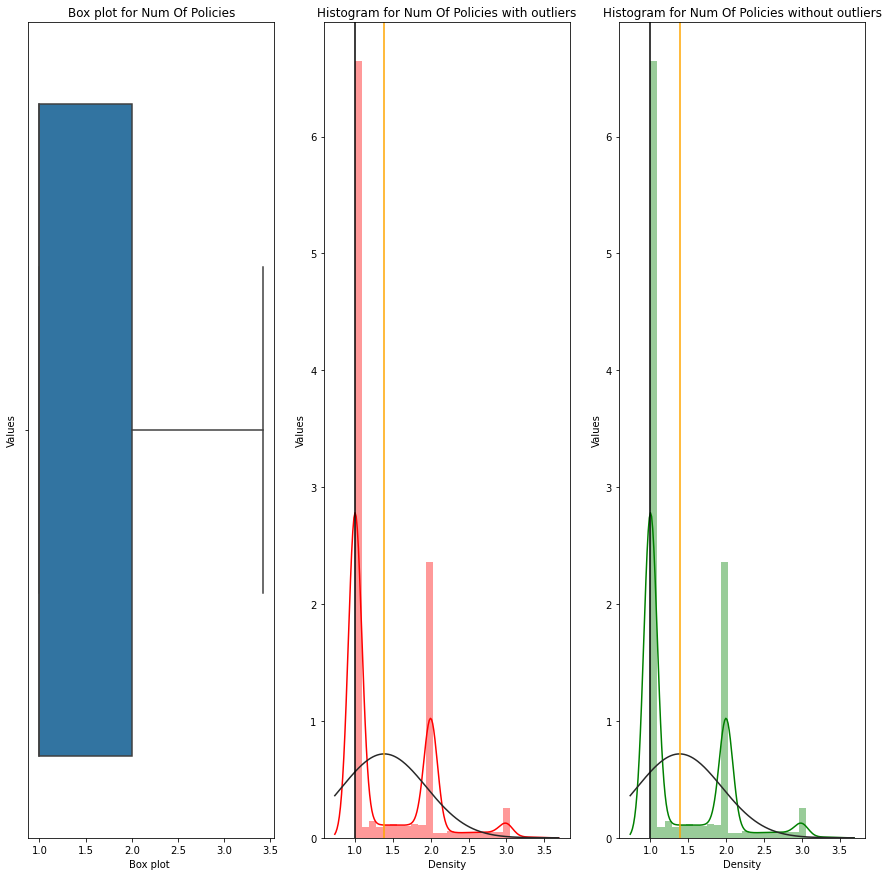

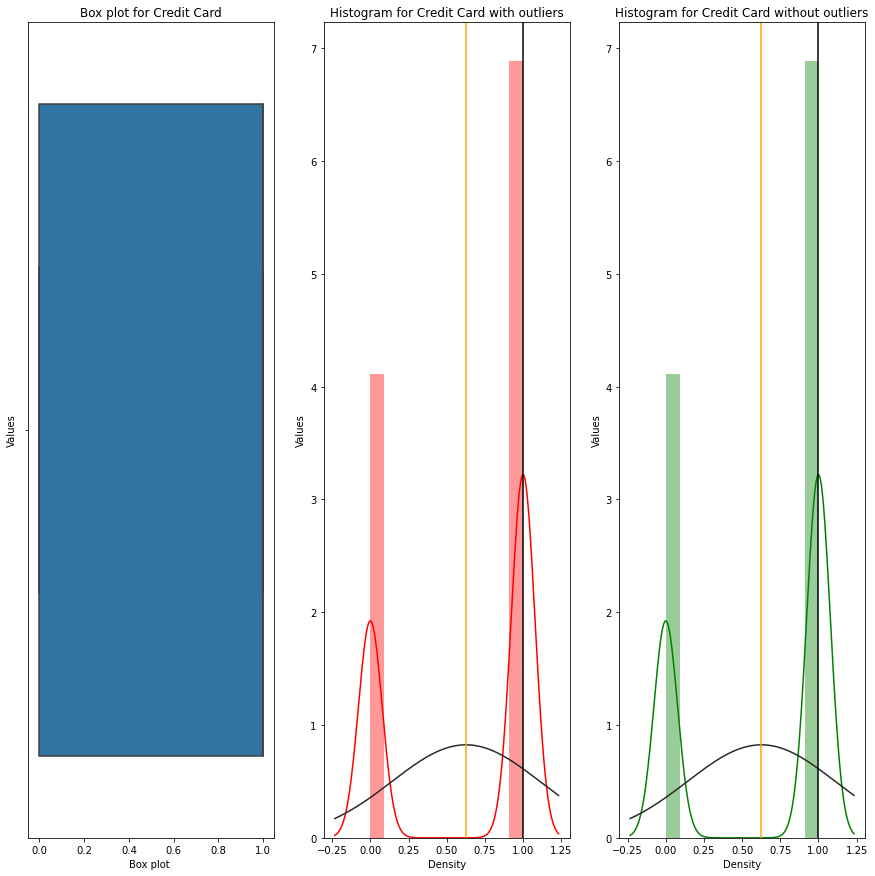

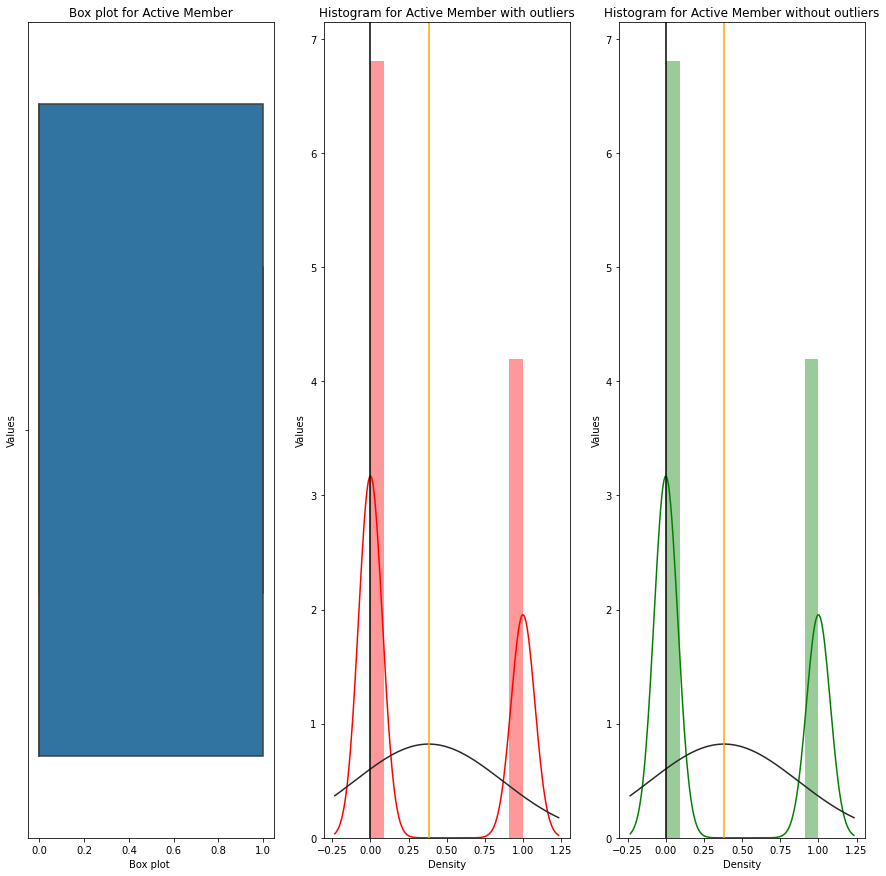

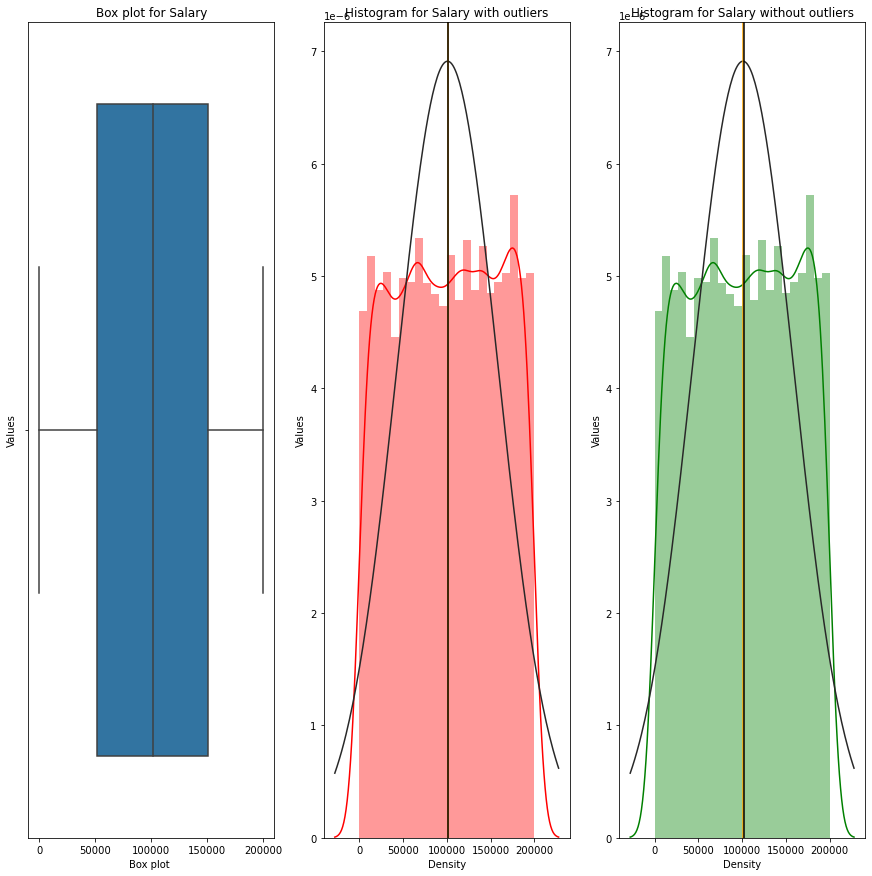

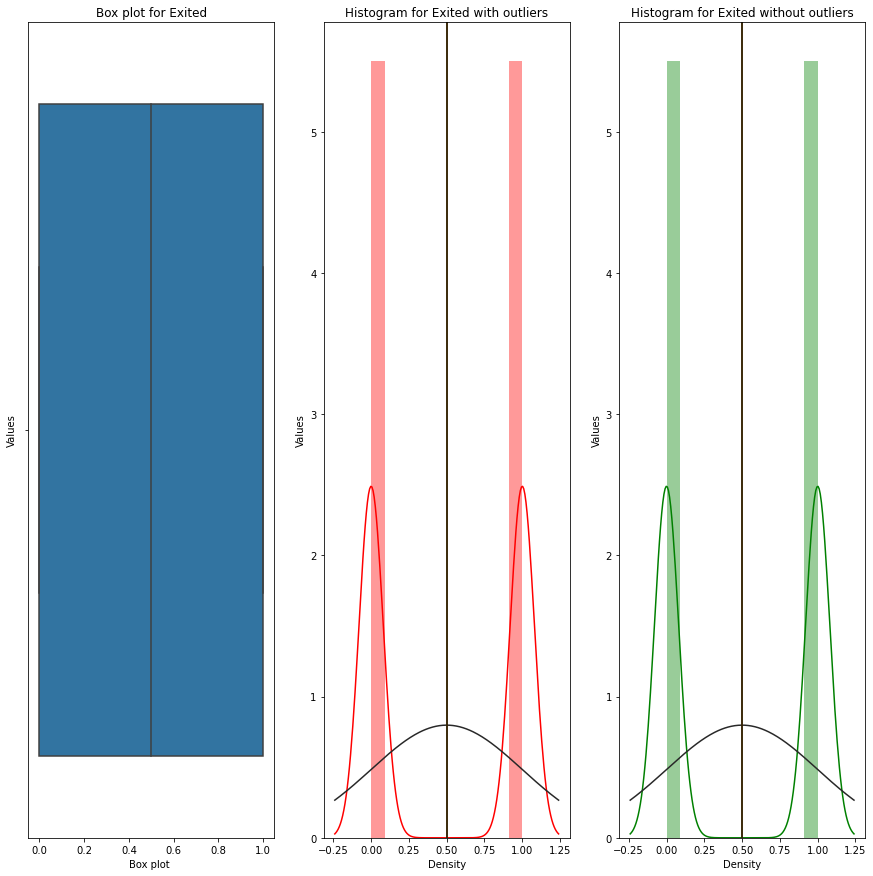

In [26]:
for col in df_new.columns:
    odt_plots(df_new,col)

In [27]:
# The outliers are replaced 
for col in df_new.columns:
    df_new = outlier_treatment(df_new,col)

column Credit Score does not have any outliers
column Geography does not have any outliers
column Gender does not have any outliers
column Age does not have any outliers
column Tenure does not have any outliers
column Balance has outliers and they are  136      49512.550000
1632    191864.510000
1797     49113.750000
3008    191775.650000
3302     49508.790000
3351    191402.820000
3449    191808.730000
4272    191523.090000
4318     49572.730000
5020     49157.090000
5470    191665.210000
6135    191091.740000
6620    191614.340373
7251     49149.235852
8115     49041.183887
8134     49415.217201
8213    191613.842252
9326     48620.027339
Name: Balance, dtype: float64
column Num Of Policies does not have any outliers
column Credit Card does not have any outliers
column Active Member does not have any outliers
column Salary does not have any outliers
column Exited does not have any outliers


### Performing Regression Analysis

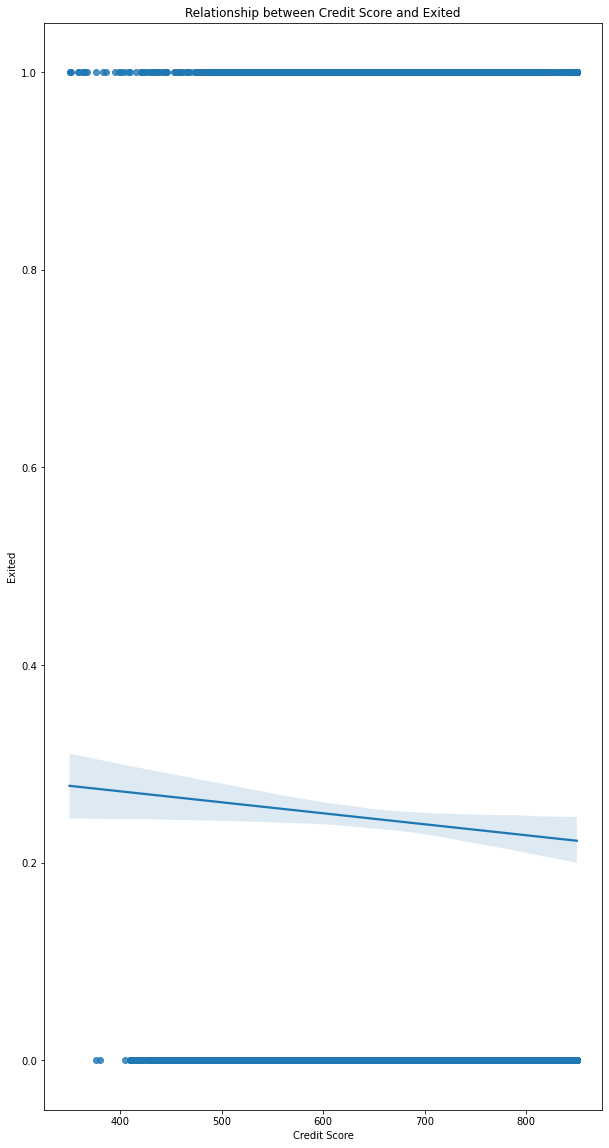

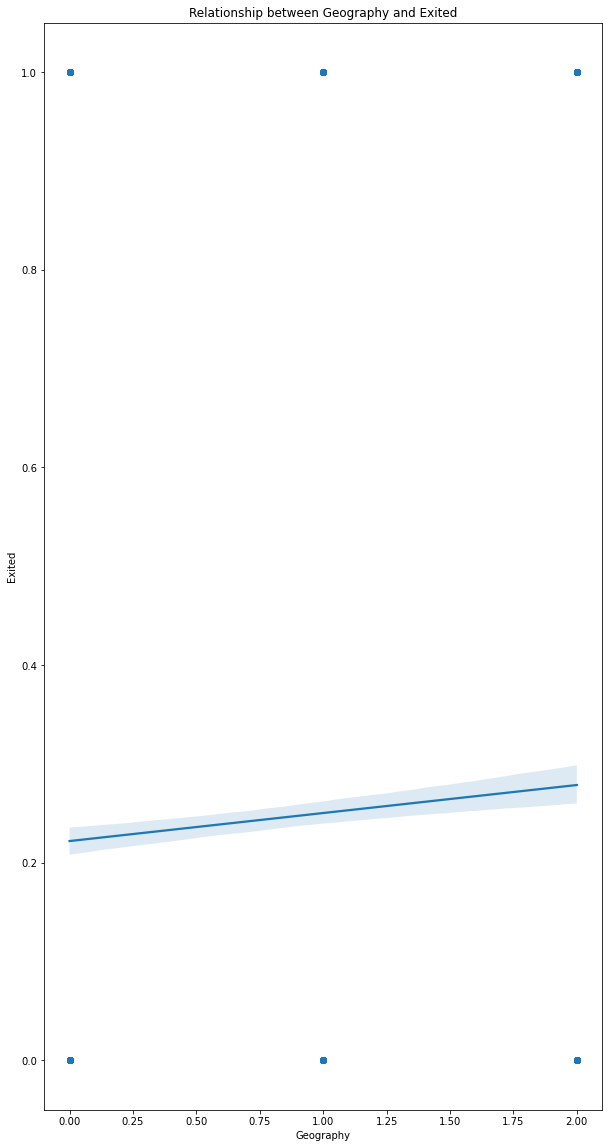

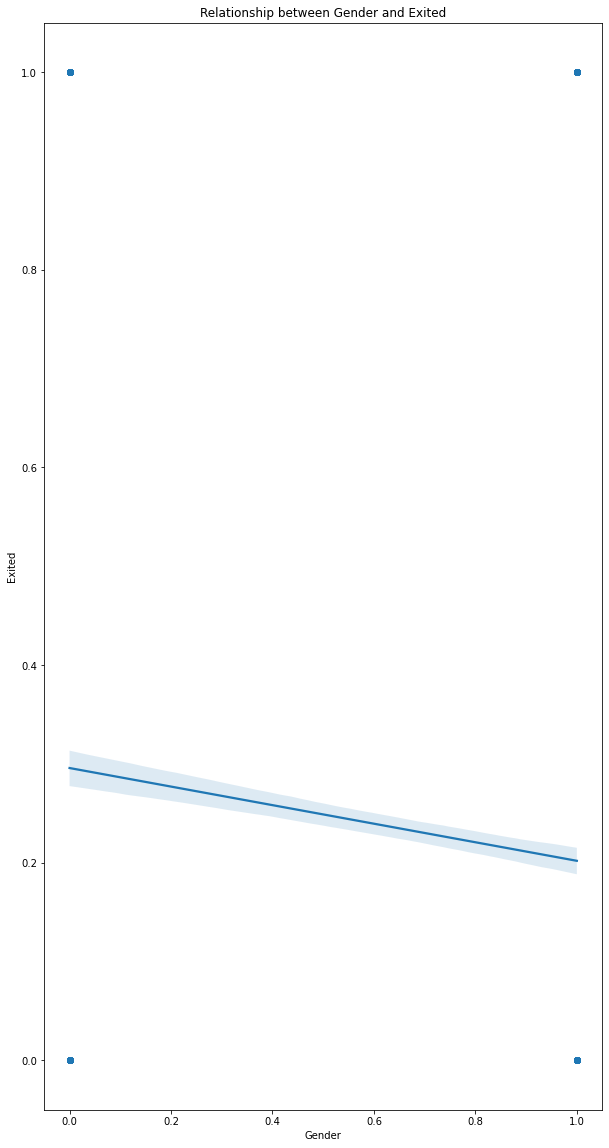

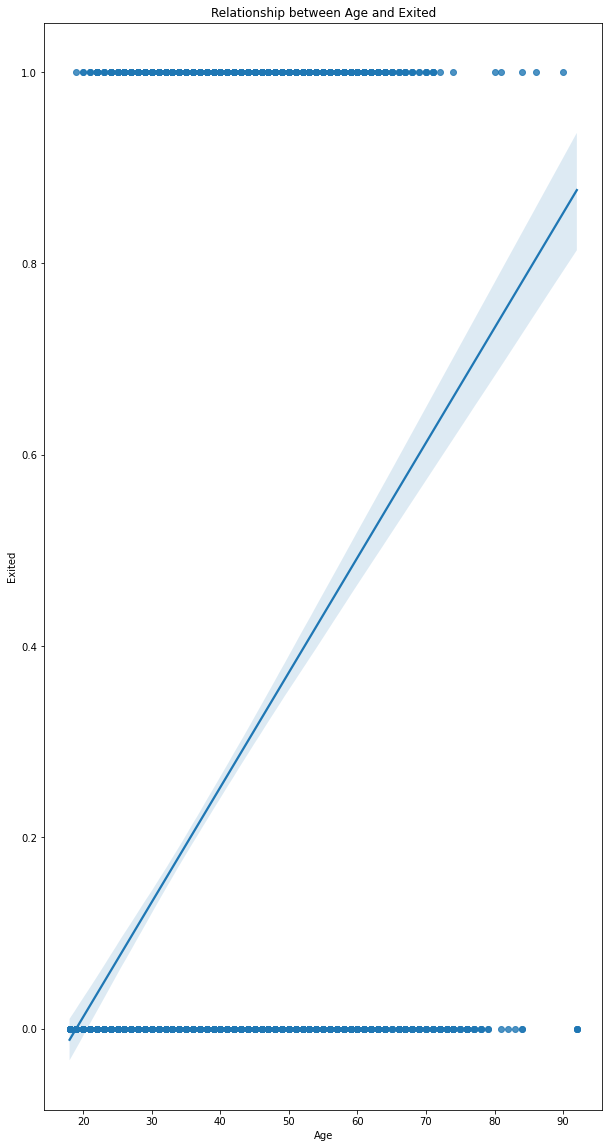

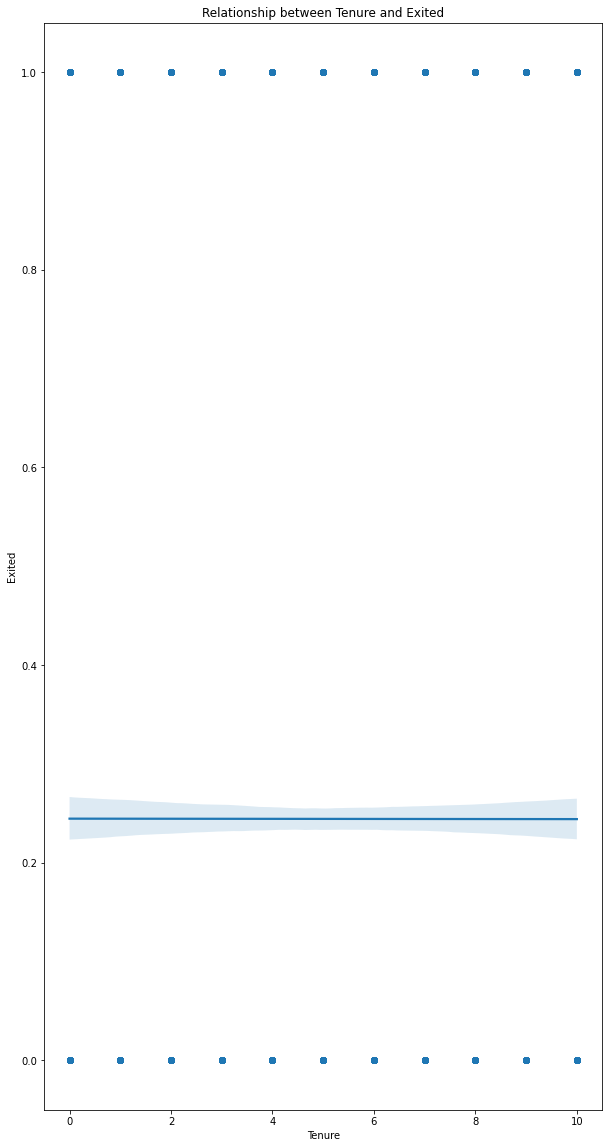

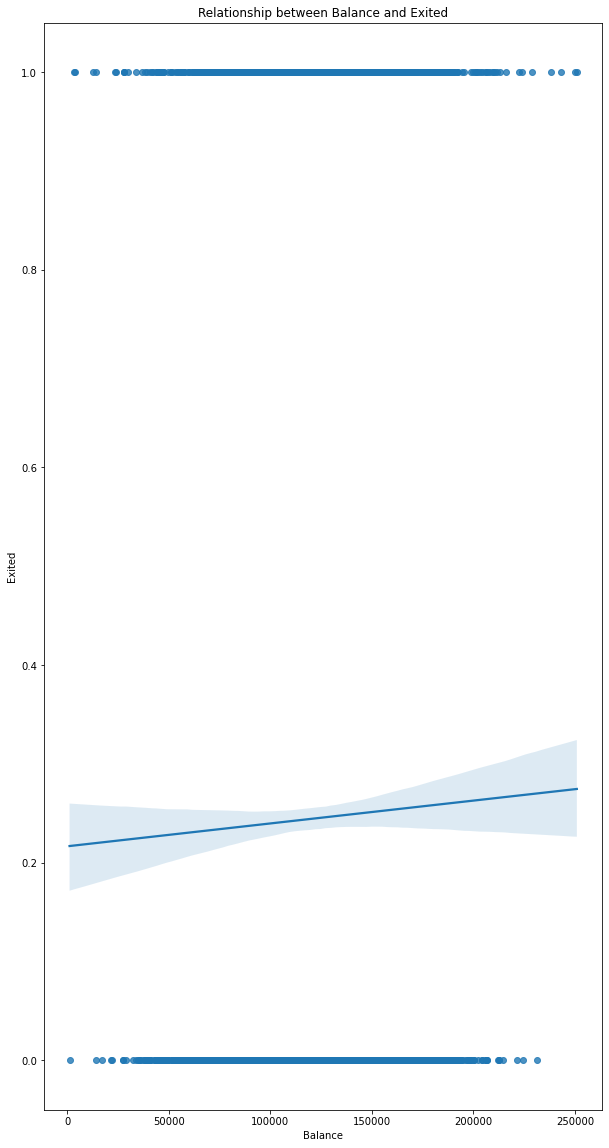

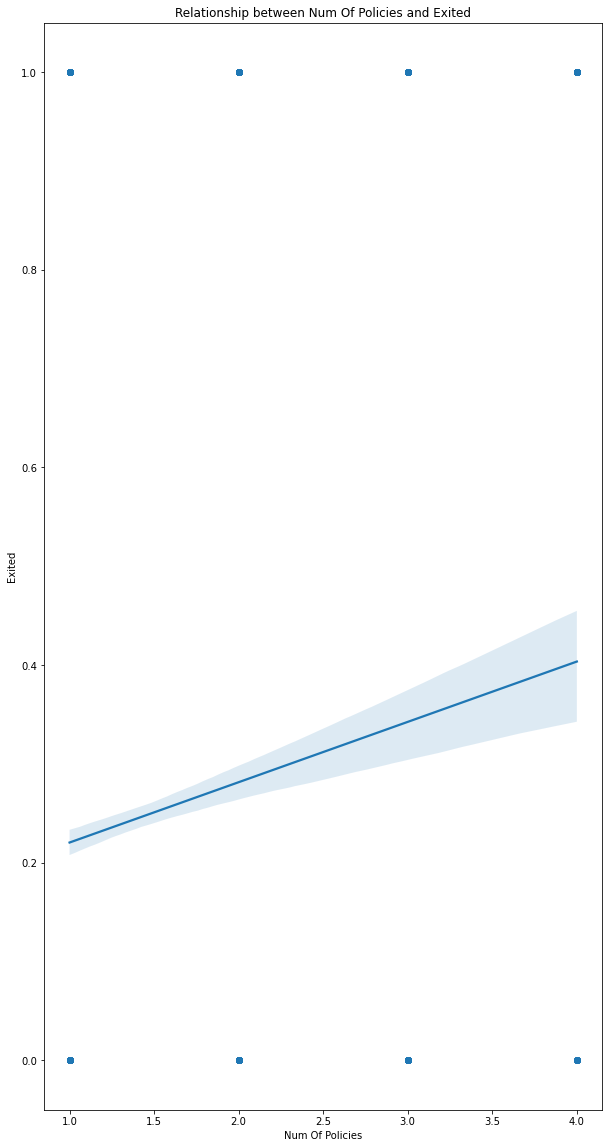

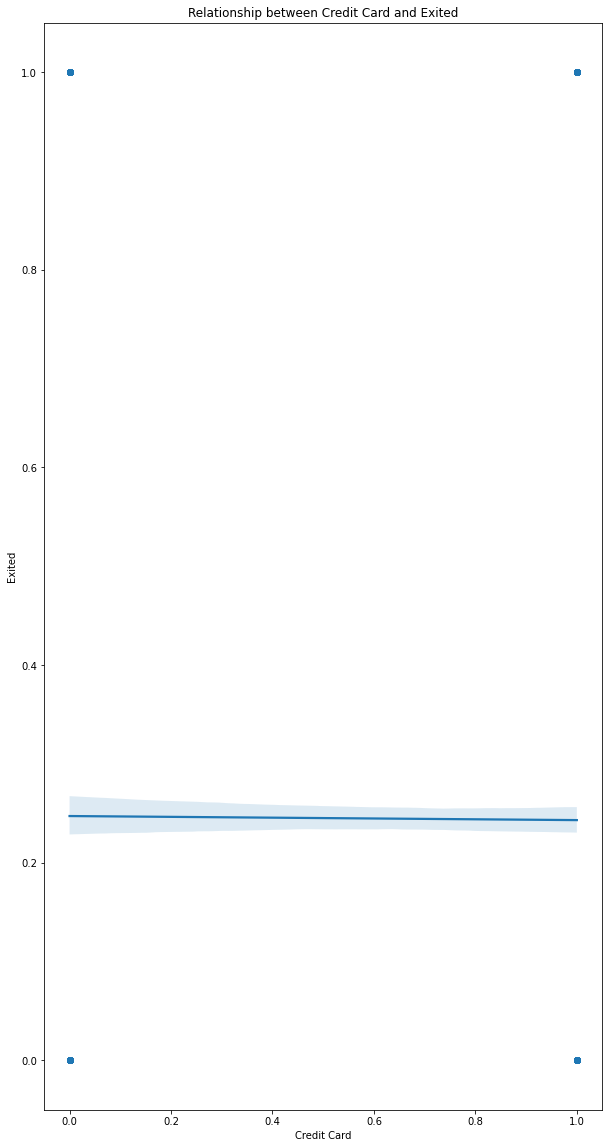

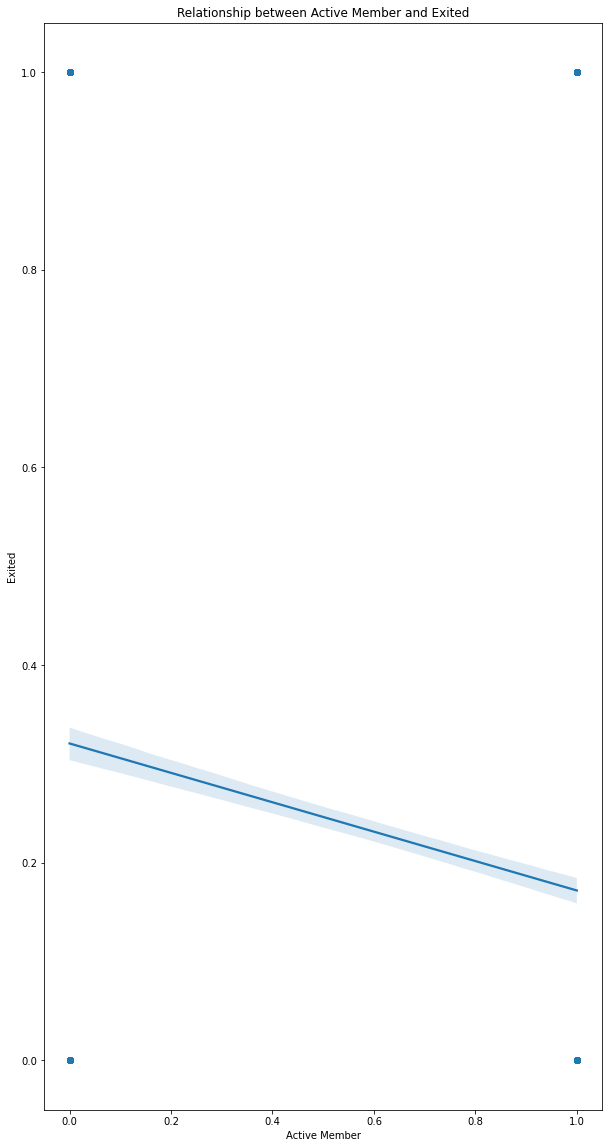

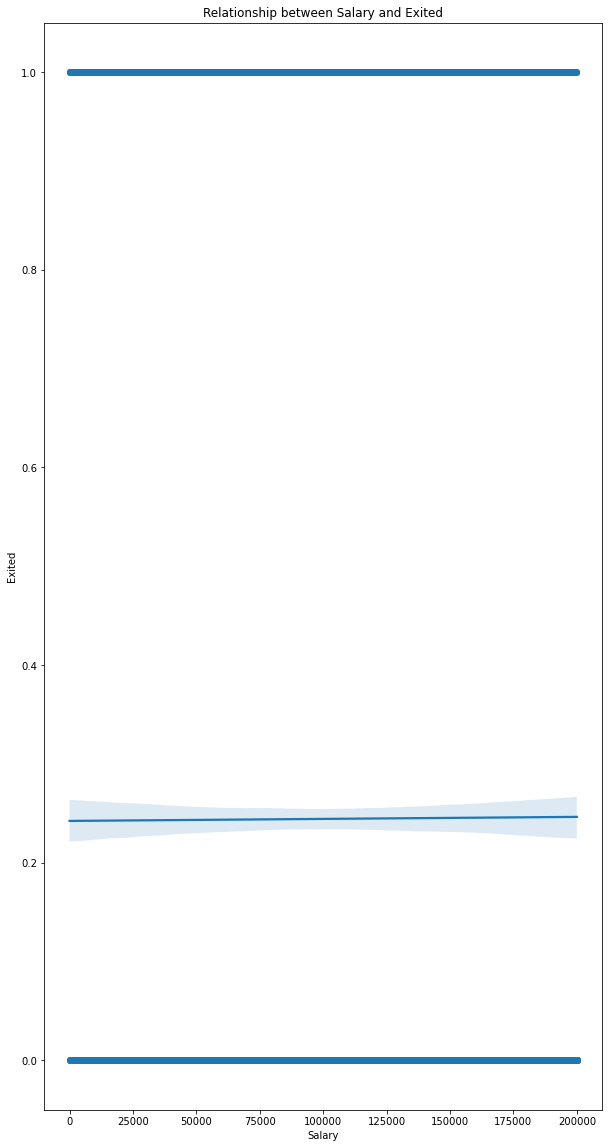

In [28]:
for col in df.columns:
    if col != "Exited":
        
        f,ax = plt.subplots(figsize = (10,20))
        
        sns.regplot(x = df[col] , y = df["Exited"]).set_title(f'Relationship between {col} and Exited')


In [29]:

def correlation_target(data , target_col):
    data_new = data.drop([target_col] , axis =1)
    indep_cols = data_new.columns
    
    correlation_result = []
    
    for col in indep_cols:
        correlation_result.append(data[target_col].corr(data[col]))
        
    # Transpose is used coz , dataframe has 2 columns, the correlation_result has 8 columns.
    
    result_df = pd.DataFrame([indep_cols,correlation_result] , index=["Variable","Correlation"]).T
    
    # print(indep_cols,correlation_result)
    
    return result_df.sort_values("Correlation" , ascending = False)

In [30]:
correlation_target(df_new,"Exited")

,Variable,Correlation
3,Age,0.415317
6,Num Of Policies,0.047691
5,Balance,0.016579
9,Salary,0.003703
4,Tenure,-0.001333
0,Credit Score,-0.034064
1,Geography,-0.075381
7,Credit Card,-0.153978
2,Gender,-0.299876
8,Active Member,-0.372386


<AxesSubplot:>

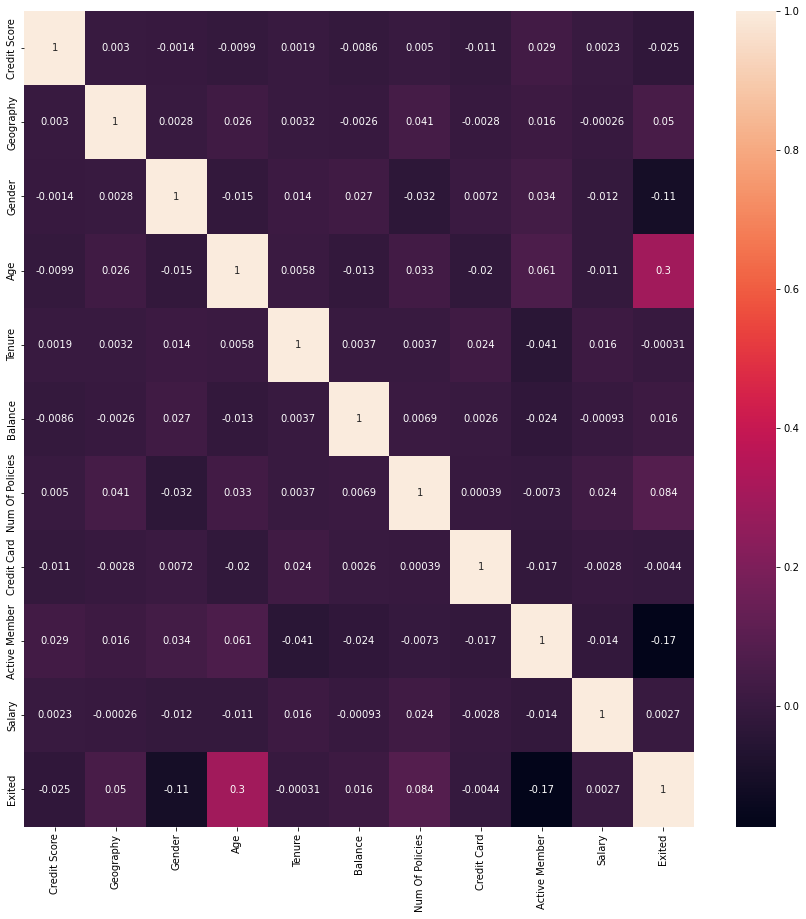

In [31]:
## To get the equations, we must check --- Multicollinearity 

corr = df.corr()
f,ax = plt.subplots(figsize =(15,15))
sns.heatmap(corr,annot = True)

# annot  = True--> displays the values

In [32]:
def vif_factor(indep_var):
    vif_df = pd.DataFrame()
    vif_df["Features"] = indep_var.columns
    vif_df["VIF"]= [variance_inflation_factor(indep_var.values,i) for i in range(indep_var.shape[1]) ]

    return vif_df.sort_values("VIF" , ascending = False)

In [33]:
vif_factor(df.drop("Exited" , axis  = 1))

,Features,VIF
0,Credit Score,23.145706
5,Balance,13.563418
3,Age,12.489416
6,Num Of Policies,6.215752
9,Salary,3.955542
4,Tenure,3.822182
7,Credit Card,3.233611
2,Gender,2.192972
1,Geography,2.097205
8,Active Member,2.058259


### Performing Principal Component Analysis 

In [34]:
# Implementing PCA inorder to remove the multicollinearity

def pca_apply(x):
    
    col = []
    len_columns = len(x.columns)  
    
    from sklearn.preprocessing import StandardScaler
    
    x = StandardScaler().fit_transform(x)
    
    from sklearn.decomposition import PCA
    
    for i in range(1,len_columns):
        pca = PCA(n_components = i)
        p_component = pca.fit_transform(x)
        
# EVR ---> Explained Variance Ration( how much information each of the p_components is taking in)

        evr = np.cumsum(pca.explained_variance_ratio_)
        
        if evr[i-1] > 0.9:
            
            n_components = i
            break
            
    print(evr)
    
# Creating a DataFrame

    for i in range(1,n_components+1):
        
        col.append("pc_" + str(i))
        
        
    pca_df = pd.DataFrame(data = p_component , columns=col)
    
    return pca_df


In [47]:
df_new.head()
df_new.shape

(9476, 11)

In [52]:
x = df_new.drop("Exited",axis = 1)
y = df_new[["Exited"]]

In [53]:
df_pca = pca_apply(x)

[0.13445378 0.24026948 0.34557833 0.44705478 0.54624394 0.64311787
 0.73772503 0.82922844 0.91660474]


In [54]:
df_pca

,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6,pc_7,pc_8,pc_9
0,0.087714,1.966996,-2.028693,0.161410,-0.748227,-0.056853,1.016786,-0.733647,-0.473949
1,-1.352523,-0.078472,2.170265,1.590130,2.418596,-0.225822,-0.922514,1.069597,0.631036
2,1.120129,0.826520,-0.756205,-1.981714,0.115457,0.203169,0.190159,-2.274899,0.760340
3,0.506671,1.524851,1.659050,0.203497,0.238662,-1.157312,0.562121,-0.330974,0.083984
4,0.169817,-0.157551,0.307678,0.369290,-0.289299,0.171955,-0.655405,-1.383327,-1.250284
...,...,...,...,...,...,...,...,...,...
9471,-1.012901,-1.054819,0.280329,1.033588,-0.179807,1.546114,0.189061,-1.534266,0.315844
9472,-0.415126,-0.698646,1.486146,-0.087945,-0.299149,-0.941281,0.011746,-0.843899,-0.355495
9473,1.022826,-0.092067,-0.790159,0.541254,-1.022164,1.003568,-0.205795,0.170852,1.573902
9474,-1.118302,0.705570,1.359490,-1.777018,1.656355,1.658144,0.746384,-0.196436,-0.585856


In [55]:
df_pca.corr()

,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6,pc_7,pc_8,pc_9
pc_1,1.000000e+00,1.567284e-16,-3.253166e-17,7.422458e-17,3.729427e-17,-7.436587e-17,1.430235e-16,-5.530694e-17,-1.292805e-16
pc_2,1.567284e-16,1.000000e+00,1.484581e-16,1.018036e-16,4.499191e-16,-2.633777e-16,2.693480e-16,-4.289092e-16,-6.265350e-17
pc_3,-3.253166e-17,1.484581e-16,1.000000e+00,-1.931029e-16,-3.078203e-16,-1.003844e-16,-2.686103e-16,4.137260e-16,-4.939807e-16
pc_4,7.422458e-17,1.018036e-16,-1.931029e-16,1.000000e+00,3.536114e-17,-1.416595e-16,1.148160e-16,1.553870e-17,-2.252456e-16
pc_5,3.729427e-17,4.499191e-16,-3.078203e-16,3.536114e-17,1.000000e+00,-3.484917e-16,-3.458568e-16,1.451779e-16,1.592014e-16
pc_6,-7.436587e-17,-2.633777e-16,-1.003844e-16,-1.416595e-16,-3.484917e-16,1.000000e+00,-3.440175e-17,2.372030e-16,-1.946864e-16
pc_7,1.430235e-16,2.693480e-16,-2.686103e-16,1.148160e-16,-3.458568e-16,-3.440175e-17,1.000000e+00,-1.233162e-16,-3.054555e-16
pc_8,-5.530694e-17,-4.289092e-16,4.137260e-16,1.553870e-17,1.451779e-16,2.372030e-16,-1.233162e-16,1.000000e+00,6.559346e-17
pc_9,-1.292805e-16,-6.265350e-17,-4.939807e-16,-2.252456e-16,1.592014e-16,-1.946864e-16,-3.054555e-16,6.559346e-17,1.000000e+00


In [56]:
vif_factor(df_pca)

,Features,VIF
0,pc_1,1.0
1,pc_2,1.0
2,pc_3,1.0
3,pc_4,1.0
4,pc_5,1.0
5,pc_6,1.0
6,pc_7,1.0
7,pc_8,1.0
8,pc_9,1.0


### Model Building

In [57]:
# Function for train_test_split

def train_and_test_split(x,y,test_size = 0.3,random_state = 100):
    
    return  train_test_split(x,y,test_size = test_size,random_state = random_state)


In [58]:
def build_model(model,model_name,x,y):
    
    x_train,x_test,y_train,y_test = train_and_test_split(x,y)
    
    model.fit(x_train,y_train)
    
    y_pred = model.predict(x_test)
    
    r2score = r2_score(y_test,y_pred)
    
    rmse = np.sqrt(mean_squared_error(y_test,y_pred))
    
    temp = [model_name,r2score,rmse]
    
    return temp

In [59]:
build_model(LinearRegression(),"Linear Regression",df_pca,y)

['Linear Regression', 0.33031627660714435, 0.40916533367748953]

In [62]:
def build_multiple_models(x,y):
    
    col_names = ["Model_Name" , "R2 Score" ,"RMSE"]
    
    result_df  = pd.DataFrame(columns = col_names)
    
    result_df.loc[len(result_df)] = build_model(LinearRegression(),"Linear Regression",x,y)
    result_df.loc[len(result_df)] = build_model(Lasso(),"Lasso ",x,y)
    result_df.loc[len(result_df)] = build_model(Ridge(),"Ridge ",x,y)
    result_df.loc[len(result_df)] = build_model(DecisionTreeRegressor(),"Decision Tree Regression",x,y)
    result_df.loc[len(result_df)] = build_model(KNeighborsRegressor(),"KNN Regression",x,y)
    result_df.loc[len(result_df)] = build_model(SVR(),"Support Vector Regression",x,y)
    result_df.loc[len(result_df)] = build_model(RandomForestRegressor(),"Random Forest Regression",x,y)
    result_df.loc[len(result_df)] = build_model(AdaBoostRegressor(),"AdaBoost Regression",x,y)
    result_df.loc[len(result_df)] = build_model(GradientBoostingRegressor(),"GBoost Regression",x,y)
    result_df.loc[len(result_df)] = build_model(XGBRegressor(),"XGBoost Regression",x,y)

    
    
    return result_df.sort_values("R2 Score" ,ascending=False)

In [63]:
build_multiple_models(df_pca,y)

,Model_Name,R2 Score,RMSE
6,Random Forest Regression,0.428366,0.378027
5,Support Vector Regression,0.405408,0.385544
9,XGBoost Regression,0.380953,0.393392
4,KNN Regression,0.378555,0.394154
8,GBoost Regression,0.377506,0.394486
0,Linear Regression,0.330316,0.409165
2,Ridge,0.330316,0.409165
7,AdaBoost Regression,0.322491,0.411549
1,Lasso,-0.000057,0.500007
3,Decision Tree Regression,-0.149522,0.536071


### Performing Cross Validation

In [65]:
def cross_validation(x,y,fold = KFold(n_splits=10,shuffle=True)):
    
    score_lr = cross_val_score(LinearRegression(),x,y,cv = fold)
    score_ls = cross_val_score(Lasso(),x,y,cv = fold)
    score_rd = cross_val_score(Ridge(),x,y,cv = fold)
    score_dt = cross_val_score(DecisionTreeRegressor(),x,y,cv = fold)
    score_kn = cross_val_score(KNeighborsRegressor(),x,y,cv = fold)
    score_svr = cross_val_score(SVR(),x,y,cv = fold)
    score_rf = cross_val_score(RandomForestRegressor(),x,y,cv = fold)
    score_ad = cross_val_score(AdaBoostRegressor(),x,y,cv = fold)
    score_gb = cross_val_score(GradientBoostingRegressor(),x,y,cv = fold)
    score_xgb = cross_val_score(XGBRegressor(),x,y,cv = fold)
    
    score_list = [score_lr,score_ls,score_rd,score_dt,score_kn,score_svr,score_rf,score_ad,score_gb,score_xgb]
    
    model_names = ["Linear Regression" , "Lasso","Ridge","Decision Tree Regression","KNN Regression","Support Vector Regression","Random Forest Regression","AdaBoost Regression","GradientBoost Regression","XGBoost Regression"]
    
    
    result = []
    
    for i in range(0,len(model_names)):
        
        score_mean = np.mean(score_list[i])
        score_std = np.std(score_list[i])
        
        model = model_names[i]
        
        temp = [model , score_mean , score_std]
        
        result.append(temp)
        
    
    result_df = pd.DataFrame(result , columns = ["Model_Names" , "Accuracy","Standard Deviation"])
    
    return result_df.sort_values("Accuracy",ascending=False)

In [66]:
cross_validation(df_pca,y)

,Model_Names,Accuracy,Standard Deviation
6,Random Forest Regression,0.438092,0.029154
5,Support Vector Regression,0.422696,0.025617
9,XGBoost Regression,0.395148,0.033070
4,KNN Regression,0.395097,0.034049
8,GradientBoost Regression,0.373494,0.020021
0,Linear Regression,0.324661,0.023944
2,Ridge,0.324478,0.020051
7,AdaBoost Regression,0.304150,0.025394
1,Lasso,-0.000549,0.000540
3,Decision Tree Regression,-0.071902,0.042769
